# Final Comparison – DenseNet121 vs MobileNet vs EfficientNetB0



In [1]:
import json
import os
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE = Path(".")

MODEL_FILES = {
    "DenseNet121": {
        "result": BASE / "densenet121_results.json",
        "report": BASE / "densenet121_classification_report.csv",
        "model": BASE / "densenet121_best.keras"
    },
    "MobileNet": {
        "result": BASE / "mobilenet_results.json",
        "report": BASE / "mobilenet_classification_report.csv",
        "model": BASE / "mobilenet_best.keras"
    },
    "EfficientNetB0": {
        "result": BASE / "efficientnetb0_results.json",
        "report": BASE / "efficientnetb0_classification_report.csv",
        "model": BASE / "efficientnetb0_best.keras"
    }
}

## 1. Load all model results

In [2]:
rows = []

def find_cancer_row(report_df):
    # Supports common spellings such as CANCER, Cancer, ORAL_CANCER.
    candidates = []
    for idx in report_df.index.astype(str):
        normalized = idx.strip().upper().replace("-", " ").replace("_", " ")
        if "CANCER" in normalized and "NON" not in normalized and "NO CANCER" not in normalized:
            candidates.append(idx)
    return candidates[0] if candidates else None

for expected_name, paths in MODEL_FILES.items():
    if not paths["result"].exists():
        print(f"Missing: {paths['result']} — run {expected_name} notebook first.")
        continue

    with open(paths["result"], "r") as f:
        result = json.load(f)

    row = {
        "Model": result.get("model", expected_name),
        "Accuracy": result.get("accuracy", np.nan),
        "Macro Precision": result.get("macro_precision", np.nan),
        "Macro Recall": result.get("macro_recall", np.nan),
        "Macro F1": result.get("macro_f1", np.nan),
        "Test Samples": result.get("test_samples", np.nan),
        "Epochs Completed": result.get("epochs_completed", np.nan),
        "CANCER Precision": np.nan,
        "CANCER Recall": np.nan,
        "CANCER F1": np.nan,
        "Model Size (MB)": np.nan
    }

    if paths["report"].exists():
        report_df = pd.read_csv(paths["report"], index_col=0)
        cancer_row = find_cancer_row(report_df)
        if cancer_row is not None:
            row["CANCER Precision"] = float(report_df.loc[cancer_row, "precision"])
            row["CANCER Recall"] = float(report_df.loc[cancer_row, "recall"])
            row["CANCER F1"] = float(report_df.loc[cancer_row, "f1-score"])

    if paths["model"].exists():
        row["Model Size (MB)"] = paths["model"].stat().st_size / (1024 * 1024)

    rows.append(row)

comparison = pd.DataFrame(rows)

if comparison.empty:
    raise FileNotFoundError(
        "No result JSON files were found. Run DenseNet121, MobileNet and "
        "EfficientNetB0 notebooks first."
    )

comparison

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Test Samples,Epochs Completed,CANCER Precision,CANCER Recall,CANCER F1,Model Size (MB)
0,DenseNet121,0.826667,0.803951,0.820,0.810348,150,7,0.893617,0.84,0.865979,35.885970
1,MobileNet,0.886667,0.868392,0.900,0.878450,150,7,0.966292,0.86,0.910053,20.215068
2,EfficientNetB0,0.853333,0.838203,0.875,0.845390,150,7,0.964286,0.81,0.880435,25.350634


## 2. Rank the models

In [3]:
# For oral-cancer classification, Macro F1 is used as the primary comparison metric.
# Tie-breakers: Accuracy, then CANCER Recall.
comparison = comparison.sort_values(
    by=["Macro F1", "Accuracy", "CANCER Recall"],
    ascending=[False, False, False],
    na_position="last"
).reset_index(drop=True)

comparison.insert(0, "Rank", range(1, len(comparison) + 1))

display(
    comparison.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "CANCER Precision": "{:.4f}",
        "CANCER Recall": "{:.4f}",
        "CANCER F1": "{:.4f}",
        "Model Size (MB)": "{:.2f}"
    })
)

comparison.to_csv("model_comparison.csv", index=False)
print("Saved: model_comparison.csv")

,Rank,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Test Samples,Epochs Completed,CANCER Precision,CANCER Recall,CANCER F1,Model Size (MB)
0,1,MobileNet,0.8867,0.8684,0.9000,0.8784,150,7,0.9663,0.8600,0.9101,20.22
1,2,EfficientNetB0,0.8533,0.8382,0.8750,0.8454,150,7,0.9643,0.8100,0.8804,25.35
2,3,DenseNet121,0.8267,0.8040,0.8200,0.8103,150,7,0.8936,0.8400,0.8660,35.89


Saved: model_comparison.csv


## 3. Overall metric comparison graph

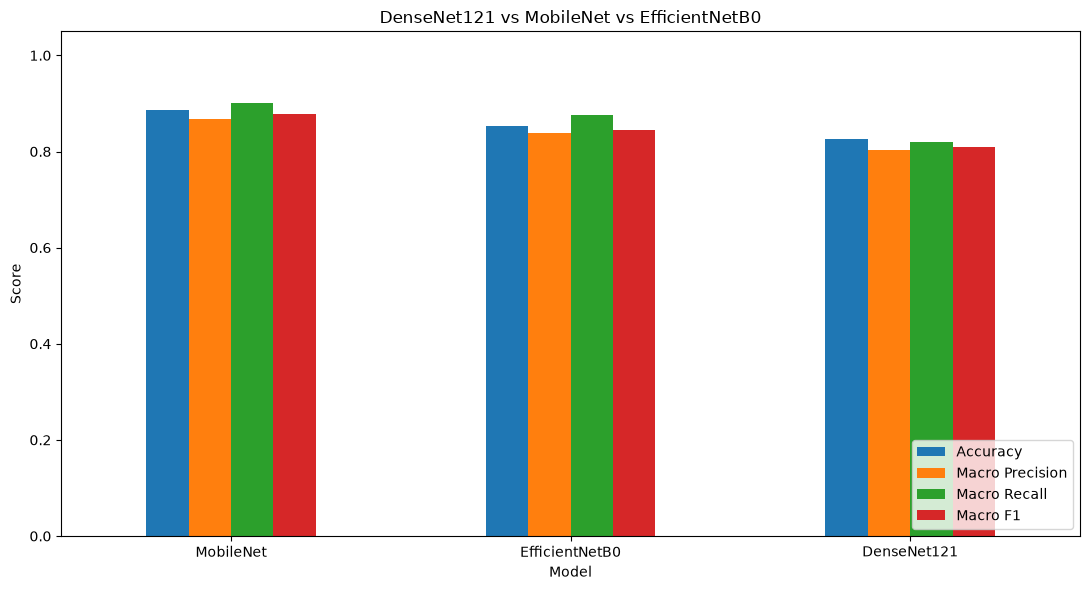

In [4]:
metrics = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]

plot_df = comparison.set_index("Model")[metrics]

ax = plot_df.plot(kind="bar", figsize=(11, 6))
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("DenseNet121 vs MobileNet vs EfficientNetB0")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("model_comparison_metrics.png", dpi=200)
plt.show()

## 4. CANCER-class comparison

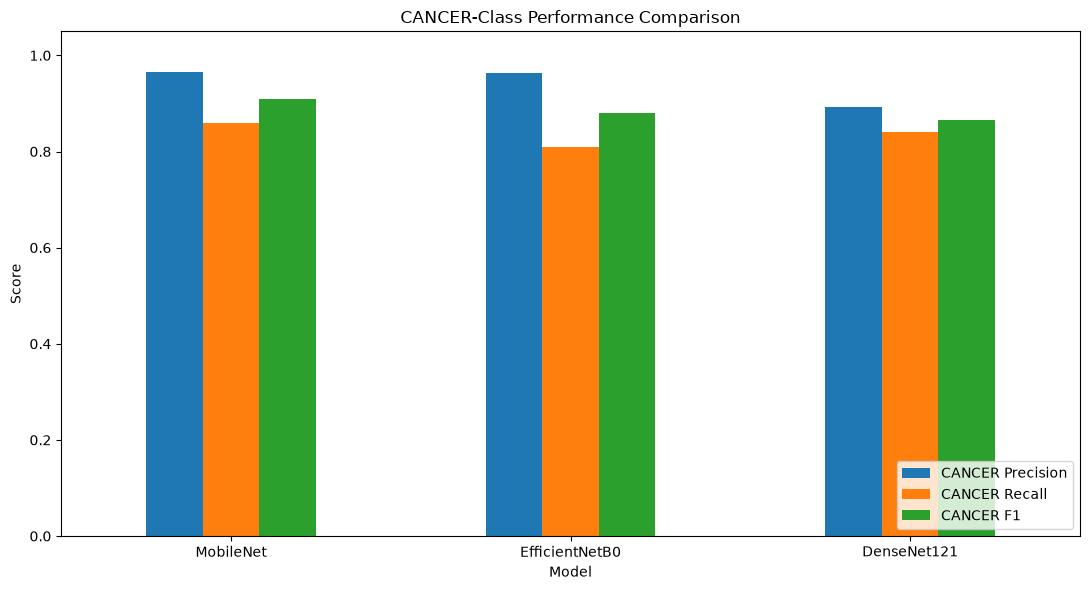

In [5]:
cancer_metrics = ["CANCER Precision", "CANCER Recall", "CANCER F1"]

if comparison[cancer_metrics].notna().any().any():
    cancer_df = comparison.set_index("Model")[cancer_metrics]
    ax = cancer_df.plot(kind="bar", figsize=(11, 6))
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Score")
    ax.set_title("CANCER-Class Performance Comparison")
    plt.xticks(rotation=0)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig("cancer_class_comparison.png", dpi=200)
    plt.show()
else:
    print("Per-class report files were not found; CANCER-class chart skipped.")

## 5. Select and save the best model

In [6]:
best_row = comparison.iloc[0]
best_name = str(best_row["Model"])

# Map the model name in the JSON to the expected file definition.
key_lookup = {k.lower(): k for k in MODEL_FILES}
normalized_best = best_name.lower()

selected_key = None
for key in MODEL_FILES:
    if key.lower() == normalized_best:
        selected_key = key
        break

if selected_key is None:
    # Fallback for slightly different JSON naming.
    if "dense" in normalized_best:
        selected_key = "DenseNet121"
    elif "efficient" in normalized_best:
        selected_key = "EfficientNetB0"
    elif "mobile" in normalized_best:
        selected_key = "MobileNet"
    else:
        raise ValueError(f"Cannot map winning model name: {best_name}")

source_model = MODEL_FILES[selected_key]["model"]
final_model = BASE / "best_oral_cancer_model.keras"

if source_model.exists():
    shutil.copy2(source_model, final_model)
    print("Best model copied to:", final_model)
else:
    print("Best model file not found:", source_model)

best_info = {
    "best_model": selected_key,
    "selection_rule": "Highest Macro F1; tie-break by Accuracy; then CANCER Recall",
    "accuracy": None if pd.isna(best_row["Accuracy"]) else float(best_row["Accuracy"]),
    "macro_precision": None if pd.isna(best_row["Macro Precision"]) else float(best_row["Macro Precision"]),
    "macro_recall": None if pd.isna(best_row["Macro Recall"]) else float(best_row["Macro Recall"]),
    "macro_f1": None if pd.isna(best_row["Macro F1"]) else float(best_row["Macro F1"]),
    "cancer_recall": None if pd.isna(best_row["CANCER Recall"]) else float(best_row["CANCER Recall"]),
    "final_model_path": str(final_model)
}

with open("best_model_selection.json", "w") as f:
    json.dump(best_info, f, indent=2)

print(json.dumps(best_info, indent=2))

Best model copied to: best_oral_cancer_model.keras
{
  "best_model": "MobileNet",
  "selection_rule": "Highest Macro F1; tie-break by Accuracy; then CANCER Recall",
  "accuracy": 0.8866666666666667,
  "macro_precision": 0.8683919690550745,
  "macro_recall": 0.8999999999999999,
  "macro_f1": 0.8784498784498784,
  "cancer_recall": 0.86,
  "final_model_path": "best_oral_cancer_model.keras"
}


## 6. Use the selected best model for prediction

In [7]:
import tensorflow as tf
from tensorflow.keras.models import load_model

from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from tensorflow.keras.applications.mobilenet import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess

with open("best_model_selection.json", "r") as f:
    best_info = json.load(f)

best_name = best_info["best_model"]
best_model = load_model("best_oral_cancer_model.keras")

# Read class mapping from the winner's result JSON.
result_path = MODEL_FILES[best_name]["result"]
with open(result_path, "r") as f:
    winning_result = json.load(f)

class_indices = winning_result["class_indices"]
CLASS_NAMES = {int(v): k for k, v in class_indices.items()}
target_size = tuple(winning_result.get("image_size", [100, 100]))

if best_name == "DenseNet121":
    selected_preprocess = densenet_preprocess
elif best_name == "MobileNet":
    selected_preprocess = mobilenet_preprocess
elif best_name == "EfficientNetB0":
    selected_preprocess = efficientnet_preprocess
else:
    raise ValueError("Unknown best model: " + best_name)

print("Loaded best model:", best_name)
print("Classes:", CLASS_NAMES)

Loaded best model: MobileNet
Classes: {0: 'CANCER', 1: 'NON CANCER'}


In [8]:
def predict_with_best_model(image_path, show=True):
    img = tf.keras.utils.load_img(image_path, target_size=target_size)
    x = tf.keras.utils.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = selected_preprocess(x)

    probs = best_model.predict(x, verbose=0)[0]
    idx = int(np.argmax(probs))
    label = CLASS_NAMES[idx]
    confidence = float(probs[idx]) * 100.0

    if show:
        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"{best_name}: {label} ({confidence:.2f}%)")
        plt.show()

    print("Best Model :", best_name)
    print("Prediction :", label)
    print("Confidence :", f"{confidence:.2f}%")
    print("Probabilities:", {
        CLASS_NAMES[i]: float(probs[i])
        for i in range(len(probs))
    })

    return label, confidence, probs


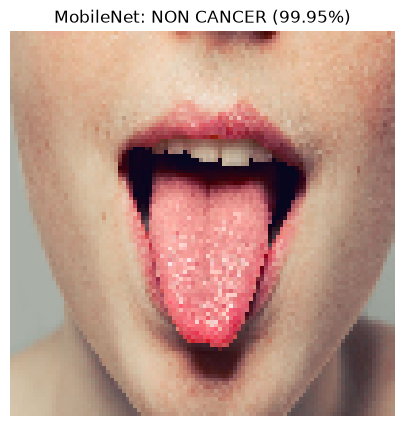

Best Model : MobileNet
Prediction : NON CANCER
Confidence : 99.95%
Probabilities: {'CANCER': 0.0005051027983427048, 'NON CANCER': 0.9994949102401733}


('NON CANCER',
 99.94949102401733,
 array([5.051028e-04, 9.994949e-01], dtype=float32))

In [9]:

predict_with_best_model('./Data_subsets/test/NON CANCER/152.jpeg')


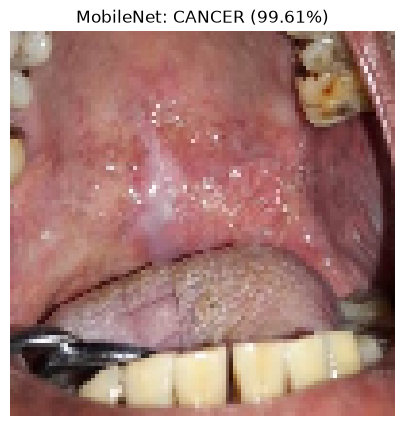

Best Model : MobileNet
Prediction : CANCER
Confidence : 99.61%
Probabilities: {'CANCER': 0.9960675239562988, 'NON CANCER': 0.003932460676878691}


('CANCER', 99.60675239562988, array([0.9960675 , 0.00393246], dtype=float32))

In [10]:
predict_with_best_model('./Data_subsets/test/CANCER/221.jpeg')